# Sentiment Analysis Using Natural Language Processing

## Datheon – Machine Learning & Data Science Internship

### Objective
To develop an NLP-based text classification system that identifies the sentiment of customer reviews using machine learning algorithms.

### Algorithms
1. Multinomial Naive Bayes
2. Logistic Regression

### Text Processing Techniques
- Lowercasing
- HTML tag removal
- Punctuation removal
- Stopword removal
- Lemmatization
- TF-IDF Vectorization

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

Dataset loaded successfully!

Dataset Shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 1.1 KB

Sentiment Distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64
NLTK resources downloaded successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\91967\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\91967\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\91967\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\91967\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\91967\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\91967\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,review_text,cleaned_review
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...
2,"Average performance, decent for the price poin...",average performance decent price point nothing...
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...
5,Customer support helped resolve my setup quest...,customer support helped resolve setup question...
6,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...
8,"Not worth the money, plenty of better alternat...",worth money plenty better alternative available
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...


Training samples: 7
Testing samples: 3
TF-IDF transformation completed!
Training feature matrix: (7, 46)
Testing feature matrix: (3, 46)
Total vocabulary size: 46
Both models trained successfully!
Naive Bayes Predictions: ['positive' 'positive' 'positive']
Logistic Regression Predictions: ['positive' 'positive' 'positive']
Actual Sentiments: <ArrowStringArray>
['negative', 'negative', 'positive']
Length: 3, dtype: str
Model Accuracy Comparison
-------------------------
Multinomial Naive Bayes: 33.33%
Logistic Regression: 33.33%


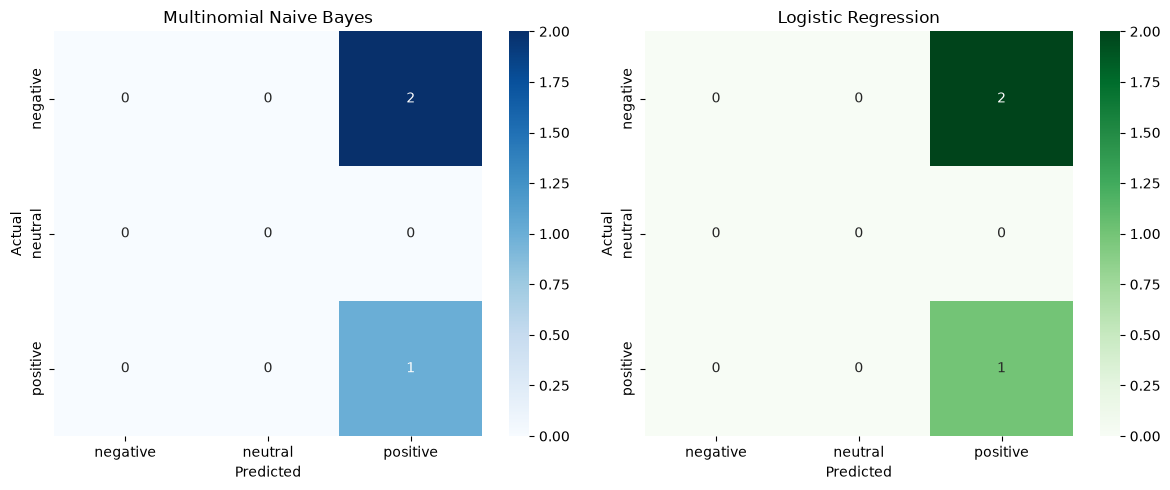

,review_text,cleaned_review
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...
2,"Average performance, decent for the price poin...",average performance decent price point nothing...
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...
5,Customer support helped resolve my setup quest...,customer support helped resolve setup question...
6,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...


Both models retrained successfully!

Original Review: This product is amazing and works perfectly!
Cleaned Review: product amazing work perfectly
Naive Bayes Prediction: positive
Logistic Regression Prediction: positive

Original Review: Very poor quality. I am extremely disappointed.
Cleaned Review: poor quality extremely disappointed
Naive Bayes Prediction: positive
Logistic Regression Prediction: positive

Original Review: The product is average and works as expected.
Cleaned Review: product average work expected
Naive Bayes Prediction: positive
Logistic Regression Prediction: positive

Original Review: The product is excellent and I absolutely love it!
Cleaned Review: product excellent absolutely love
Naive Bayes Prediction: positive
Logistic Regression Prediction: positive


(np.str_('positive'), 'positive')

In [ ]:
import pandas as pd
import numpy as np
import re
import nltk

from IPython.display import display

df = pd.read_csv("sentiment_reviews.csv")

print("Dataset loaded successfully!")
print("\nDataset Shape:", df.shape)

display(df.head(10))

print("\nDataset Information:")
df.info()

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')

print("NLTK resources downloaded successfully!")

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    tokens = word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return ' '.join(tokens)

df['cleaned_review'] = df['review_text'].apply(preprocess_text)

display(df[['review_text', 'cleaned_review']])

from sklearn.model_selection import train_test_split

X = df['cleaned_review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed!")

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("Total vocabulary size:", len(tfidf.get_feature_names_out()))

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

# Initialize models
nb_model = MultinomialNB()

lr_model = LogisticRegression(max_iter=1000)

# Train Naive Bayes
nb_model.fit(X_train_tfidf, y_train)

# Train Logistic Regression
lr_model.fit(X_train_tfidf, y_train)

print("Both models trained successfully!")

# Naive Bayes predictions
nb_predictions = nb_model.predict(X_test_tfidf)

# Logistic Regression predictions
lr_predictions = lr_model.predict(X_test_tfidf)

print("Naive Bayes Predictions:", nb_predictions)
print("Logistic Regression Predictions:", lr_predictions)
print("Actual Sentiments:", y_test.values)

nb_accuracy = accuracy_score(y_test, nb_predictions)

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Model Accuracy Comparison")
print("-------------------------")
print(f"Multinomial Naive Bayes: {nb_accuracy * 100:.2f}%")
print(f"Logistic Regression: {lr_accuracy * 100:.2f}%")

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

labels = ['negative', 'neutral', 'positive']

nb_cm = confusion_matrix(y_test, nb_predictions, labels=labels)
lr_cm = confusion_matrix(y_test, lr_predictions, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(nb_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=axes[0])

axes[0].set_title('Multinomial Naive Bayes')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels, ax=axes[1])

axes[1].set_title('Logistic Regression')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

stop_words = set(stopwords.words('english'))

stop_words -= {'not', 'no', 'never', 'nor'}

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    tokens = word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return ' '.join(tokens)

df['cleaned_review'] = df['review_text'].apply(preprocess_text)

display(df[['review_text', 'cleaned_review']])

X = df['cleaned_review']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

nb_model = MultinomialNB()
lr_model = LogisticRegression(max_iter=1000)

nb_model.fit(X_train_tfidf, y_train)
lr_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)
lr_predictions = lr_model.predict(X_test_tfidf)

print("Both models retrained successfully!")

def predict_sentiment(review):

    cleaned = preprocess_text(review)

    vectorized = tfidf.transform([cleaned])

    nb_result = nb_model.predict(vectorized)[0]
    lr_result = lr_model.predict(vectorized)[0]

    print("\nOriginal Review:", review)
    print("Cleaned Review:", cleaned)
    print("Naive Bayes Prediction:", nb_result)
    print("Logistic Regression Prediction:", lr_result)

    return nb_result, lr_result

predict_sentiment("This product is amazing and works perfectly!")

predict_sentiment("Very poor quality. I am extremely disappointed.")

predict_sentiment("The product is average and works as expected.")
user_review = input("Enter your product or movie review: ")

predict_sentiment(user_review)

from sklearn.metrics import classification_report, accuracy_score

print("UPDATED MODEL PERFORMANCE")

print("\nNaive Bayes Accuracy:",
      accuracy_score(y_test, nb_predictions) * 100, "%")

print("\nLogistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions) * 100, "%")

print("\nNaive Bayes Classification Report:")
print(classification_report(y_test, nb_predictions, zero_division=0))

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, lr_predictions, zero_division=0))



##  Conclusion

In this project, a Natural Language Processing (NLP) sentiment classification pipeline was developed to classify customer reviews into positive, negative and neutral sentiments.

Text preprocessing techniques such as lowercasing, punctuation removal, tokenization, stopword removal and lemmatization were applied.

TF-IDF was used to convert textual data into numerical features.

Two machine learning algorithms, Multinomial Naive Bayes and Logistic Regression, were trained and evaluated using accuracy, classification reports and confusion matrices.

An interactive prediction function was also developed to classify custom user reviews.

The project demonstrates the implementation of an end-to-end NLP sentiment classification pipeline. However, the small dataset limits the reliability and generalization of the model. A larger and more balanced dataset is required for better performance.